# COVID-19 Global Impact Dashboard

Analysis of Our World in Data (OWID) COVID-19 data.



## 1. Setup and Data Loading

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Find the project folder: the notebook may be run from <project>/notebooks (normal) or from <project> itself.
if os.path.isdir('../data'):
    BASE = '..'
elif os.path.isdir('data'):
    BASE = '.'
else:
    BASE = '.'          # neither exists: create data/ and outputs/ next to the notebook
DATA_DIR   = f'{BASE}/data'
OUT_DIR    = f'{BASE}/outputs'
DATA_PATH  = f'{DATA_DIR}/owid-covid-data.csv'
CLEAN_PATH = f'{DATA_DIR}/covid_data_cleaned.csv'
RAW_URL    = 'https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
print('Working folder :', os.getcwd())
print('Data folder    :', os.path.abspath(DATA_DIR))
print('Outputs folder :', os.path.abspath(OUT_DIR))

# Every number used in the executive summary is stored here and saved to outputs/key_numbers.json
# (guarded so that re-running this cell alone does NOT wipe results from later cells)
if 'key_numbers' not in globals():
    key_numbers = {}

Working folder : C:\Users\lenovo\Desktop\32\notebooks
Data folder    : C:\Users\lenovo\Desktop\32\data
Outputs folder : C:\Users\lenovo\Desktop\32\outputs


In [2]:
# Load the dataset (falls back to the OWID GitHub copy if the local file is missing)
if os.path.exists(DATA_PATH):
    print('Loading local file:', os.path.abspath(DATA_PATH))
else:
    print(f'{DATA_PATH} not found -> downloading from OWID GitHub (put the CSV in the data folder to avoid this).')
df = pd.read_csv(DATA_PATH if os.path.exists(DATA_PATH) else RAW_URL, parse_dates=['date'])

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Locations (incl. aggregates): {df['location'].nunique()}")
df.head()

Loading local file: C:\Users\lenovo\Desktop\32\data\owid-covid-data.csv
Dataset shape: (429435, 67)
Date range: 2020-01-01 to 2024-08-14
Locations (incl. aggregates): 255


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths_per_million,new_deaths_per_million,new_deaths_smoothed_per_million,reproduction_rate,icu_patients,icu_patients_per_million,hosp_patients,hosp_patients_per_million,weekly_icu_admissions,weekly_icu_admissions_per_million,weekly_hosp_admissions,weekly_hosp_admissions_per_million,total_tests,new_tests,total_tests_per_thousand,new_tests_per_thousand,new_tests_smoothed,new_tests_smoothed_per_thousand,positive_rate,tests_per_case,tests_units,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_boosters,new_vaccinations,new_vaccinations_smoothed,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,new_vaccinations_smoothed_per_million,new_people_vaccinated_smoothed,new_people_vaccinated_smoothed_per_hundred,stringency_index,population_density,median_age,aged_65_older,aged_70_older,gdp_per_capita,extreme_poverty,cardiovasc_death_rate,diabetes_prevalence,female_smokers,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,54.42,18.6,2.58,1.34,1803.99,NaN,597.03,9.59,NaN,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,54.42,18.6,2.58,1.34,1803.99,NaN,597.03,9.59,NaN,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,54.42,18.6,2.58,1.34,1803.99,NaN,597.03,9.59,NaN,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,54.42,18.6,2.58,1.34,1803.99,NaN,597.03,9.59,NaN,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,54.42,18.6,2.58,1.34,1803.99,NaN,597.03,9.59,NaN,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN


## 2. Data Cleaning and Preprocessing

In [3]:
# 2.1 Missing values in key columns (raw data)
key_columns = ['total_cases', 'total_deaths', 'total_vaccinations', 'people_fully_vaccinated', 'population']
print("Missing values in key columns (raw):")
print(df[key_columns].isnull().sum())

Missing values in key columns (raw):
total_cases                 17631
total_deaths                17631
total_vaccinations         344018
people_fully_vaccinated    351374
population                      0
dtype: int64


In [4]:
# 2.2 Keep real countries only.
# OWID aggregates (World, continents, income groups) have no continent value.
# OWID_* ISO codes also cover England, Scotland, Wales, Northern Ireland, Northern Cyprus and Kosovo,
# which would double count (e.g. the UK) or are not countries, so they are removed too.
df_countries = df[df['continent'].notna()].copy()
df_countries = df_countries[~df_countries['iso_code'].str.startswith('OWID_', na=False)]
df_countries = df_countries.sort_values(['location', 'date']).reset_index(drop=True)

print(f"Rows kept: {len(df_countries):,} of {len(df):,}")
print(f"Countries analysed: {df_countries['location'].nunique()}")
key_numbers['countries_analysed'] = int(df_countries['location'].nunique())

Rows kept: 395,311 of 429,435
Countries analysed: 237


In [5]:
# 2.3 Data quality checks
print(f"Rows with negative new cases:  {(df_countries['new_cases'] < 0).sum()}")
print(f"Rows with negative new deaths: {(df_countries['new_deaths'] < 0).sum()}")
print(f"Rows with zero/missing population: {(~(df_countries['population'] > 0)).sum()}")

# Negative daily values are data corrections, not real counts -> set to missing
for c in ['new_cases', 'new_deaths']:
    df_countries.loc[df_countries[c] < 0, c] = np.nan

Rows with negative new cases:  0
Rows with negative new deaths: 0
Rows with zero/missing population: 0


In [6]:
# 2.4 Missing-value handling (documented assumptions)
# - Cumulative columns can never decrease, so gaps are forward-filled within each country.
#   Leading gaps (before a country's first report) stay missing - they are NOT treated as zero.
# - Daily 'new_*' columns are left as missing (sums/means skip them).
cumulative_cols = ['total_cases', 'total_deaths', 'total_vaccinations',
                   'people_vaccinated', 'people_fully_vaccinated']
df_countries[cumulative_cols] = df_countries.groupby('location')[cumulative_cols].ffill()

print("Missing values after forward-fill:")
print(df_countries[cumulative_cols + ['population']].isnull().sum())

Missing values after forward-fill:
total_cases                  3807
total_deaths                 3807
total_vaccinations         121433
people_vaccinated          122119
people_fully_vaccinated    134218
population                      0
dtype: int64


## 3. Deriving New Metrics

In [7]:
# Case fatality rate (%) = total deaths / total cases * 100
tc = df_countries['total_cases']
df_countries['case_fatality_rate'] = np.where(tc > 0, df_countries['total_deaths'] / tc * 100, np.nan)

# Vaccination rate (% of population fully vaccinated). A few rows exceed 100% because of
# denominator/reporting issues, so values are capped at 100.
df_countries['vaccination_rate'] = (
    df_countries['people_fully_vaccinated'] / df_countries['population'] * 100
).clip(upper=100)

# 7-day rolling averages per country (need a full 7 days of data)
grp = df_countries.groupby('location')
df_countries['new_cases_7day_avg'] = grp['new_cases'].transform(lambda x: x.rolling(7, min_periods=7).mean())
df_countries['new_deaths_7day_avg'] = grp['new_deaths'].transform(lambda x: x.rolling(7, min_periods=7).mean())
print("Derived: case_fatality_rate, vaccination_rate, new_cases_7day_avg, new_deaths_7day_avg")

Derived: case_fatality_rate, vaccination_rate, new_cases_7day_avg, new_deaths_7day_avg


In [8]:
# Doubling time (days) of cumulative cases:
#   daily growth rate r = ln(cases_today / cases_7_days_ago) / 7,  doubling time = ln(2) / r
# Only computed when cases are growing and the country has >= 1,000 cases (tiny counts are noise).
prev = df_countries.groupby('location')['total_cases'].shift(7)
with np.errstate(divide='ignore', invalid='ignore'):
    growth = np.log(df_countries['total_cases'] / prev) / 7
    valid = (prev > 0) & (growth > 0) & (df_countries['total_cases'] >= 1000)
    df_countries['doubling_time_days'] = np.where(valid, np.log(2) / growth, np.nan)
# Doubling times above one year mean growth has effectively stopped, so they are set to missing
df_countries.loc[df_countries['doubling_time_days'] > 365, 'doubling_time_days'] = np.nan

# Over the whole period growth is ~0 for most of the time, giving huge, meaningless doubling times,
# so summary statistics are shown for the first wave only (Mar-Jun 2020).
first_wave = df_countries[(df_countries['date'] >= '2020-03-01') & (df_countries['date'] <= '2020-06-30')]
dt = first_wave['doubling_time_days'].dropna()
print(f"Doubling time, Mar-Jun 2020 (days) - median: {dt.median():.1f}, 10th pct: {dt.quantile(.10):.1f}, 90th pct: {dt.quantile(.90):.1f}")

Doubling time, Mar-Jun 2020 (days) - median: 22.0, 10th pct: 6.9, 90th pct: 132.1


In [9]:
# Vaccination rollout speed per country.
#   days_to_50         = days from the FIRST recorded vaccination (first dose / first dose count) to 50% of the
#                        population fully vaccinated
#   deaths_after_start = deaths recorded after vaccination started (excludes the pre-vaccine period)
# The start is the first dose record, because the 'fully vaccinated' column often starts weeks later (or is
# reported late), which would make some countries look unrealistically fast.
# Countries whose first record is already above 5% of the population (start date missing, e.g. China) are
# excluded, because their 'days to 50%' would be meaningless.
def rollout_stats(g):
    g = g.sort_values('date')
    pop = g['population'].iloc[0]
    doses = g[['people_vaccinated', 'total_vaccinations']].max(axis=1)    # NaN-skipping max of the two columns
    full_share = g['people_fully_vaccinated'] / pop
    started, reached = doses > 0, full_share >= 0.5
    if not started.any() or not reached.any():
        return None
    if doses[started].iloc[0] / pop > 0.05:
        return None
    start_date = g.loc[started, 'date'].iloc[0]
    reach_date = g.loc[reached, 'date'].iloc[0]
    if reach_date < start_date:
        return None
    deaths = g['total_deaths']
    at_start = deaths[g['date'] == start_date].iloc[0]
    at_start = 0 if pd.isna(at_start) else at_start
    return {'days_to_50': (reach_date - start_date).days,
            'deaths_after_start': deaths.max() - at_start}

rows = {}
for loc, g in df_countries.groupby('location'):
    r = rollout_stats(g)
    if r:
        rows[loc] = r
speed = pd.DataFrame.from_dict(rows, orient='index')
print(f"Countries with a valid 'days to 50%' value: {len(speed)}")

Countries with a valid 'days to 50%' value: 111


## 4. Exploratory Data Analysis and Key Insights

In [10]:
# Per-country totals (cumulative columns -> max) used by several insights
totals = df_countries.groupby('location').agg(
    continent=('continent', 'first'),
    population=('population', 'last'),
    median_age=('median_age', 'first'),
    total_cases=('total_cases', 'max'),
    total_deaths=('total_deaths', 'max'),
)
totals['cfr_pct'] = totals['total_deaths'] / totals['total_cases'] * 100
totals['deaths_per_million'] = totals['total_deaths'] / totals['population'] * 1e6
totals = totals.join(speed)
totals['deaths_after_start_pm'] = totals['deaths_after_start'] / totals['population'] * 1e6
totals.head()

,continent,population,median_age,total_cases,total_deaths,cfr_pct,deaths_per_million,days_to_50,deaths_after_start,deaths_after_start_pm
location,,,,,,,,,,
Afghanistan,Asia,41128772,18.6,235214.0,7998.0,3.400308,194.462407,NaN,NaN,NaN
Albania,Europe,2842318,38.0,335047.0,3605.0,1.075968,1268.330989,NaN,NaN,NaN
Algeria,Africa,44903228,29.1,272139.0,6881.0,2.528487,153.240653,NaN,NaN,NaN
American Samoa,Oceania,44295,NaN,8359.0,34.0,0.406747,767.580991,NaN,NaN,NaN
Andorra,Europe,79843,NaN,48015.0,159.0,0.331147,1991.408138,202.0,63.0,789.048508


### Insight 1 - Global timeline: waves, peaks and reporting artifacts

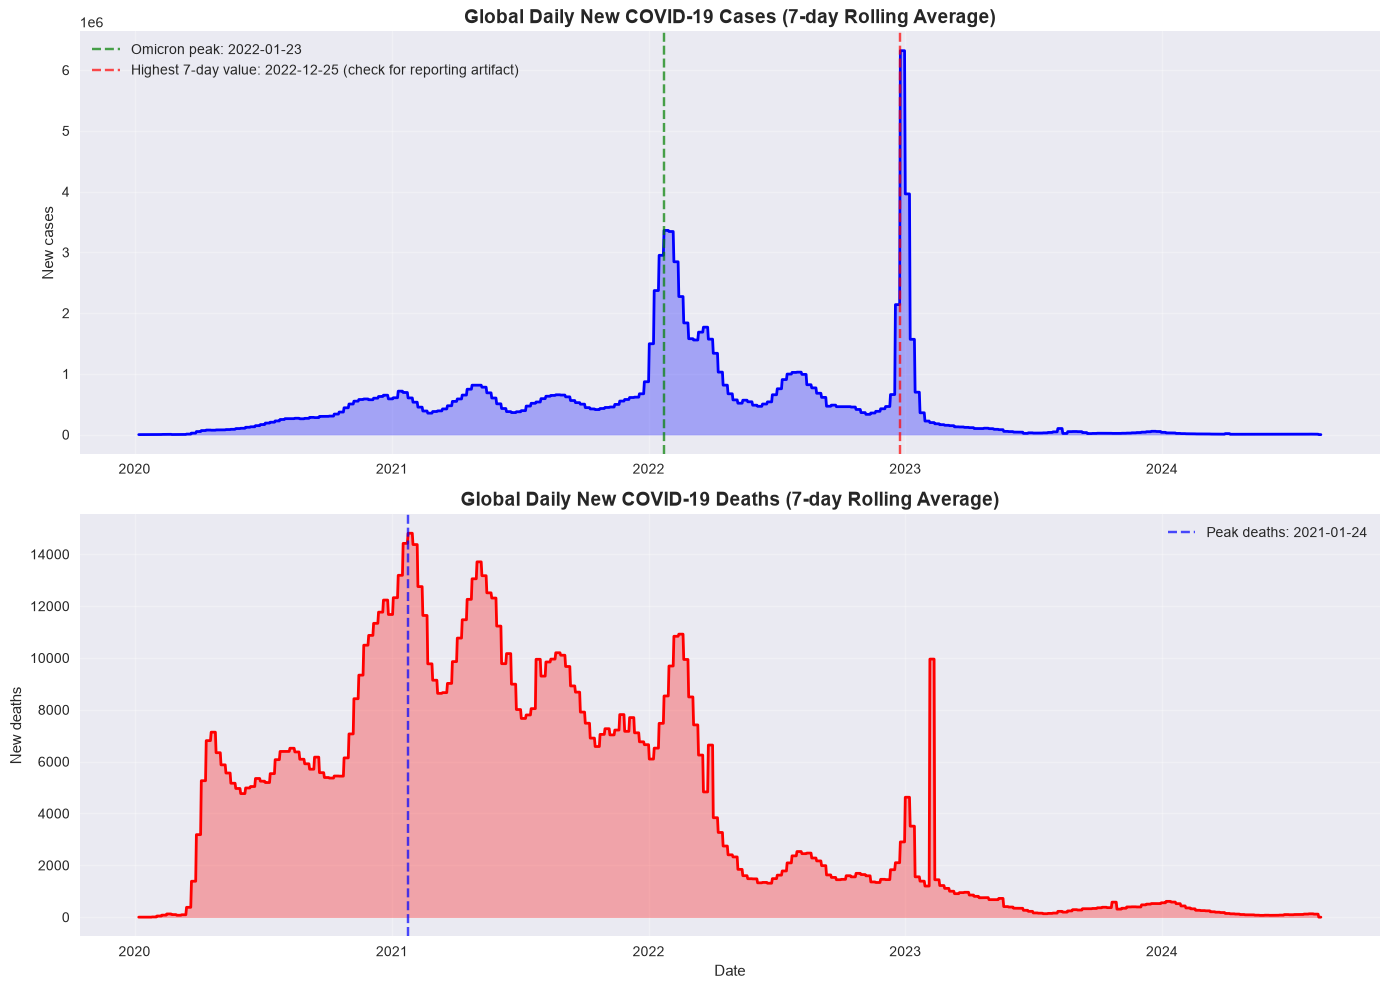

*** INSIGHT 1: Global waves ***
Highest 7-day case value: 6,319,458 on 2022-12-25
  Top countries in that window: China (84,280,665), Japan (4,213,208), United States (1,817,940)
  China alone = 86% of all cases reported in that window -> a one-country reporting effect, not a global surge
Omicron-window case peak: 3,361,213 on 2022-01-23
Peak deaths: 14,811 on 2021-01-24
  Top countries in the Jan-Feb 2023 death spike: China (49,584), United States (13,492), Japan (13,190)
At the death peak:   603,560 cases/day, 14,811 deaths/day -> 24.5 deaths per 1,000 cases
At the Omicron peak: 3,361,213 cases/day, 8,533 deaths/day -> 2.5 deaths per 1,000 cases
Note: deaths lag cases and testing/reporting changed over time, so this ratio is descriptive only.


In [11]:
global_daily = df_countries.groupby('date')[['new_cases', 'new_deaths']].sum().reset_index()
global_daily['cases_7d'] = global_daily['new_cases'].rolling(7).mean()
global_daily['deaths_7d'] = global_daily['new_deaths'].rolling(7).mean()

# Overall peaks
peak_cases_all = global_daily.loc[global_daily['cases_7d'].idxmax()]
peak_deaths = global_daily.loc[global_daily['deaths_7d'].idxmax()]

# Omicron peak, measured inside its own window so a later reporting spike cannot hide it
om = global_daily[(global_daily['date'] >= '2021-12-01') & (global_daily['date'] <= '2022-04-30')]
peak_omicron = om.loc[om['cases_7d'].idxmax()]

# Which countries cause the late-2022 case spike and the early-2023 death spike?
w = df_countries[(df_countries['date'] >= '2022-12-15') & (df_countries['date'] <= '2023-01-10')]
spike_cases = w.groupby('location')['new_cases'].sum().nlargest(3)
w = df_countries[(df_countries['date'] >= '2023-01-25') & (df_countries['date'] <= '2023-02-20')]
spike_deaths = w.groupby('location')['new_deaths'].sum().nlargest(3)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
ax1.plot(global_daily['date'], global_daily['cases_7d'], color='blue', linewidth=2)
ax1.fill_between(global_daily['date'], global_daily['cases_7d'], alpha=0.3, color='blue')
ax1.axvline(peak_omicron['date'], color='green', linestyle='--', alpha=0.7,
            label=f"Omicron peak: {peak_omicron['date'].date()}")
ax1.axvline(peak_cases_all['date'], color='red', linestyle='--', alpha=0.7,
            label=f"Highest 7-day value: {peak_cases_all['date'].date()} (check for reporting artifact)")
ax1.set_title('Global Daily New COVID-19 Cases (7-day Rolling Average)', fontsize=14, fontweight='bold')
ax1.set_ylabel('New cases'); ax1.grid(True, alpha=0.3); ax1.legend(loc='upper left')

ax2.plot(global_daily['date'], global_daily['deaths_7d'], color='red', linewidth=2)
ax2.fill_between(global_daily['date'], global_daily['deaths_7d'], alpha=0.3, color='red')
ax2.axvline(peak_deaths['date'], color='blue', linestyle='--', alpha=0.7,
            label=f"Peak deaths: {peak_deaths['date'].date()}")
ax2.set_title('Global Daily New COVID-19 Deaths (7-day Rolling Average)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Date'); ax2.set_ylabel('New deaths'); ax2.grid(True, alpha=0.3); ax2.legend(loc='upper right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/global_timeline.png', dpi=300, bbox_inches='tight')
plt.show()

# Compare the early-2021 death peak with the Omicron case peak (deaths per 1,000 reported cases)
at = global_daily.set_index('date')
c_d, d_d = at.loc[peak_deaths['date'], 'cases_7d'], at.loc[peak_deaths['date'], 'deaths_7d']
c_o, d_o = at.loc[peak_omicron['date'], 'cases_7d'], at.loc[peak_omicron['date'], 'deaths_7d']

print("*** INSIGHT 1: Global waves ***")
wc = df_countries[(df_countries['date'] >= '2022-12-15') & (df_countries['date'] <= '2023-01-10')]
top_share = spike_cases.iloc[0] / wc['new_cases'].sum() * 100
print(f"Highest 7-day case value: {peak_cases_all['cases_7d']:,.0f} on {peak_cases_all['date'].date()}")
print(f"  Top countries in that window: {', '.join(f'{k} ({v:,.0f})' for k, v in spike_cases.items())}")
print(f"  {spike_cases.index[0]} alone = {top_share:.0f}% of all cases reported in that window -> a one-country reporting effect, not a global surge")
print(f"Omicron-window case peak: {peak_omicron['cases_7d']:,.0f} on {peak_omicron['date'].date()}")
print(f"Peak deaths: {peak_deaths['deaths_7d']:,.0f} on {peak_deaths['date'].date()}")
print(f"  Top countries in the Jan-Feb 2023 death spike: {', '.join(f'{k} ({v:,.0f})' for k, v in spike_deaths.items())}")
print(f"At the death peak:   {c_d:,.0f} cases/day, {d_d:,.0f} deaths/day -> {d_d / c_d * 1000:.1f} deaths per 1,000 cases")
print(f"At the Omicron peak: {c_o:,.0f} cases/day, {d_o:,.0f} deaths/day -> {d_o / c_o * 1000:.1f} deaths per 1,000 cases")
print("Note: deaths lag cases and testing/reporting changed over time, so this ratio is descriptive only.")

key_numbers['insight1'] = {
    'highest_7d_cases': float(peak_cases_all['cases_7d']), 'highest_7d_cases_date': str(peak_cases_all['date'].date()),
    'spike_countries_cases': {k: float(v) for k, v in spike_cases.items()},
    'omicron_peak_cases': float(peak_omicron['cases_7d']), 'omicron_peak_date': str(peak_omicron['date'].date()),
    'peak_deaths': float(peak_deaths['deaths_7d']), 'peak_deaths_date': str(peak_deaths['date'].date()),
    'spike_countries_deaths': {k: float(v) for k, v in spike_deaths.items()},
    'deaths_per_1000_cases_at_death_peak': float(d_d / c_d * 1000),
    'deaths_per_1000_cases_at_omicron_peak': float(d_o / c_o * 1000),
}

### Insight 2 - Case fatality rate by country (countries with > 100K cases)

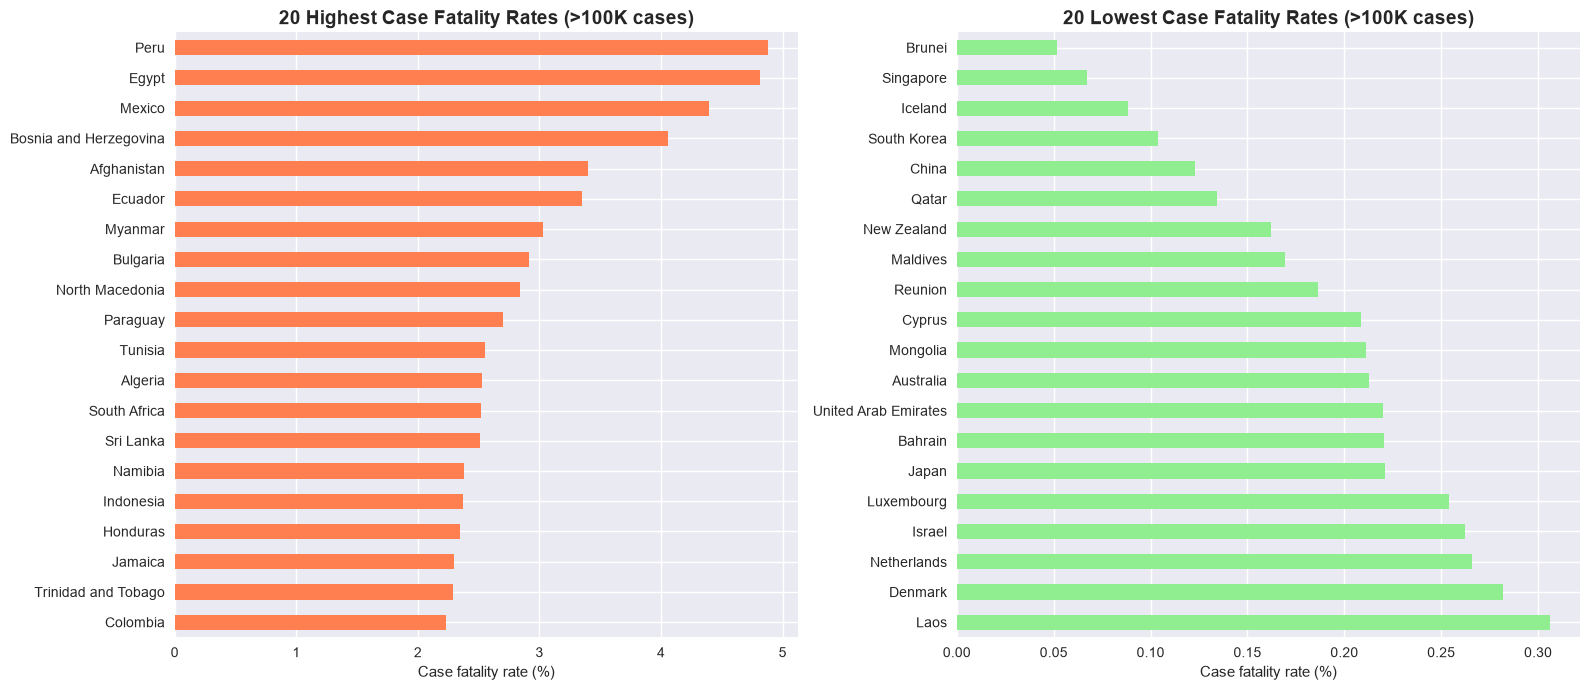

*** INSIGHT 2: Case fatality rate ***
Countries with > 100K cases: 129
Highest CFR: 4.88% (Peru)
Lowest CFR:  0.05% (Brunei)
5 lowest:   Brunei (0.05%), Singapore (0.07%), Iceland (0.09%), South Korea (0.10%), China (0.12%)
5 highest:  Peru (4.88%), Egypt (4.81%), Mexico (4.39%), Bosnia and Herzegovina (4.06%), Afghanistan (3.40%)
Caution: CFR depends on how many cases were detected (testing), not only on how deadly the disease was.


In [12]:
eligible = totals[totals['total_cases'] > 100_000].dropna(subset=['cfr_pct']).sort_values('cfr_pct')
lowest20 = eligible.head(20)
highest20 = eligible.tail(20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
highest20['cfr_pct'].plot(kind='barh', ax=ax1, color='coral')        # ascending order -> highest ends at the top
ax1.set_title('20 Highest Case Fatality Rates (>100K cases)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Case fatality rate (%)'); ax1.set_ylabel('')

lowest20['cfr_pct'].plot(kind='barh', ax=ax2, color='lightgreen')
ax2.invert_yaxis()                                                    # lowest at the top
ax2.set_title('20 Lowest Case Fatality Rates (>100K cases)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Case fatality rate (%)'); ax2.set_ylabel('')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/case_fatality_rate.png', dpi=300, bbox_inches='tight')
plt.show()

print("*** INSIGHT 2: Case fatality rate ***")
print(f"Countries with > 100K cases: {len(eligible)}")
print(f"Highest CFR: {highest20['cfr_pct'].iloc[-1]:.2f}% ({highest20.index[-1]})")
print(f"Lowest CFR:  {lowest20['cfr_pct'].iloc[0]:.2f}% ({lowest20.index[0]})")
print("5 lowest:  ", ', '.join(f'{n} ({v:.2f}%)' for n, v in lowest20['cfr_pct'].head(5).items()))
print("5 highest: ", ', '.join(f'{n} ({v:.2f}%)' for n, v in highest20['cfr_pct'].iloc[::-1].head(5).items()))
print("Caution: CFR depends on how many cases were detected (testing), not only on how deadly the disease was.")

key_numbers['insight2'] = {
    'n_countries': int(len(eligible)),
    'highest': {n: float(v) for n, v in highest20['cfr_pct'].iloc[::-1].head(5).items()},
    'lowest': {n: float(v) for n, v in lowest20['cfr_pct'].head(5).items()},
}

### Insight 3 - Did faster vaccination rollout go with lower death rates?

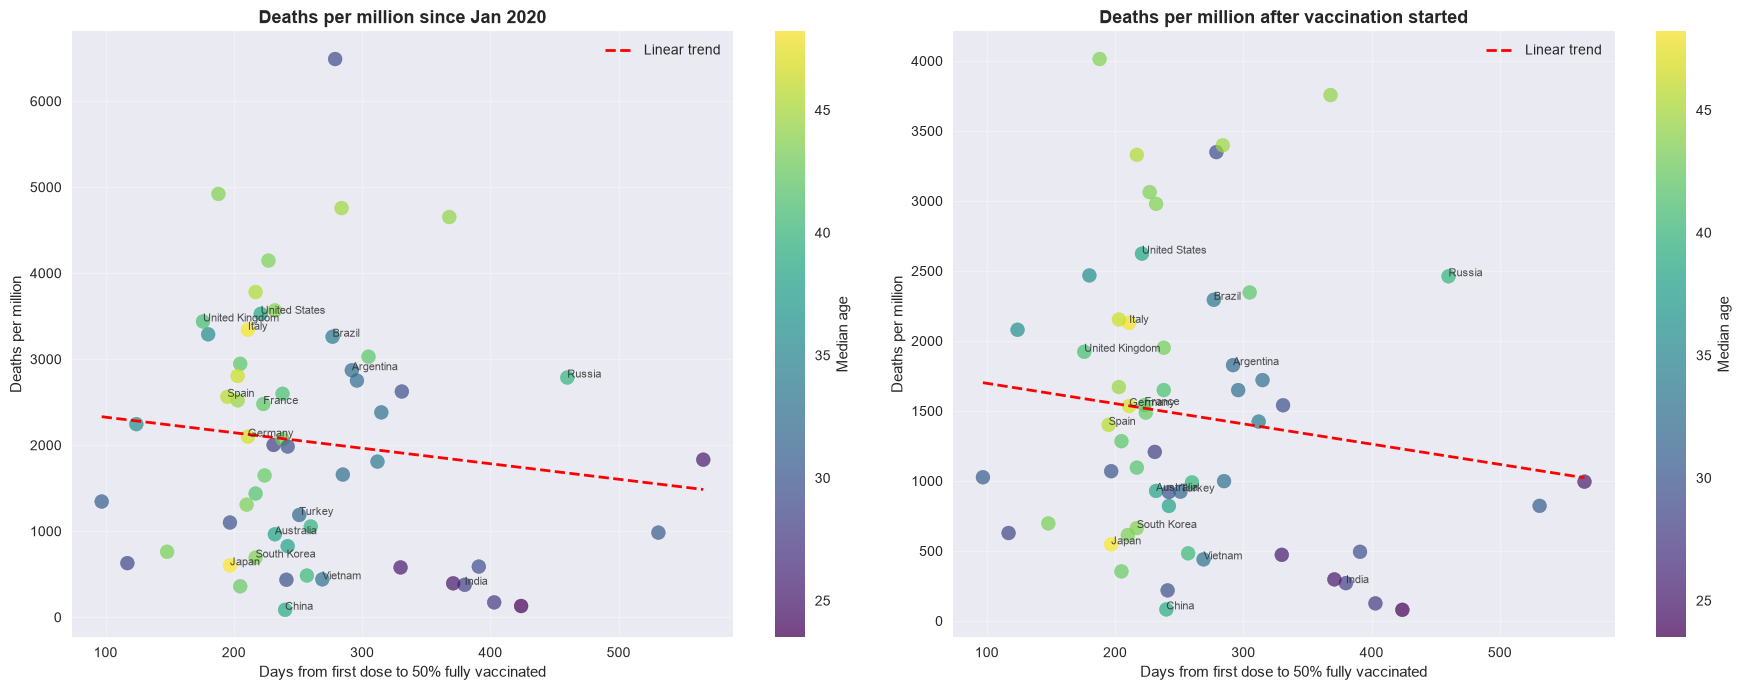

*** INSIGHT 3: Rollout speed vs deaths ***
Countries analysed: 57
Deaths since Jan 2020, Spearman:             -0.171 (p = 0.203, NOT statistically significant) -> a weak correlation (slower rollout goes with FEWER deaths)
  controlling for median age:               +0.067 (p = 0.624, NOT statistically significant) -> no meaningful correlation
Deaths after vaccination start, Spearman:    -0.177 (p = 0.189, NOT statistically significant) -> a weak correlation (slower rollout goes with FEWER deaths)
  controlling for median age:               +0.079 (p = 0.560, NOT statistically significant) -> no meaningful correlation
Caution: country-level correlation, not causation; reporting quality, variants and timing also differ.


In [13]:
def _pvalue(r, n, n_controls=0):
    """Two-sided p-value for a (partial) correlation r from n countries (t-test)."""
    try:
        from scipy.stats import t
    except ImportError:
        return np.nan
    df_ = n - 2 - n_controls
    if df_ <= 0 or abs(r) >= 1:
        return np.nan
    return float(2 * t.sf(abs(r * np.sqrt(df_ / (1 - r ** 2))), df_))

def spearman_and_partial(d, x, y, control='median_age'):
    """Spearman correlation of x and y, plus the same correlation controlling for `control`.
    Returns (rho, p_rho, partial_rho, p_partial, n)."""
    d = d[[x, y, control]].dropna()
    n = len(d)
    rho = d[x].corr(d[y], method='spearman')
    r = d.rank()
    resid = lambda a, b: a - np.polyval(np.polyfit(b, a, 1), b)
    partial = np.corrcoef(resid(r[x], r[control]), resid(r[y], r[control]))[0, 1]
    return rho, _pvalue(rho, n), partial, _pvalue(partial, n, 1), n

def describe(r):
    s = abs(r)
    strength = 'no meaningful' if s < 0.1 else 'a weak' if s < 0.3 else 'a moderate' if s < 0.5 else 'a strong'
    if s < 0.1:
        return f'{strength} correlation'
    direction = 'slower rollout goes with MORE deaths' if r > 0 else 'slower rollout goes with FEWER deaths'
    return f'{strength} correlation ({direction})'

# Countries with > 1M cases and > 1M people, valid rollout speed and median age
sel = totals[(totals['total_cases'] > 1_000_000) & (totals['population'] > 1_000_000)
             & totals['days_to_50'].notna()].copy()

rho_all, p_rho_all, partial_all, p_part_all, n_all = spearman_and_partial(sel, 'days_to_50', 'deaths_per_million')
rho_post, p_rho_post, partial_post, p_part_post, n_post = spearman_and_partial(sel, 'days_to_50', 'deaths_after_start_pm')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, ycol, ttl in [(axes[0], 'deaths_per_million', 'Deaths per million since Jan 2020'),
                      (axes[1], 'deaths_after_start_pm', 'Deaths per million after vaccination started')]:
    d = sel.dropna(subset=[ycol, 'median_age'])
    sc = ax.scatter(d['days_to_50'], d[ycol], c=d['median_age'], cmap='viridis', s=100, alpha=0.7)
    if len(d) > 2:
        z = np.polyfit(d['days_to_50'], d[ycol], 1)
        xs = np.sort(d['days_to_50'].values)
        ax.plot(xs, np.polyval(z, xs), 'r--', linewidth=2, label='Linear trend')
    for name, row in d[d['total_cases'] > 10_000_000].iterrows():
        ax.annotate(name, (row['days_to_50'], row[ycol]), fontsize=8, alpha=0.8)
    ax.set_xlabel('Days from first dose to 50% fully vaccinated')
    ax.set_ylabel('Deaths per million'); ax.set_title(ttl, fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3); ax.legend(); plt.colorbar(sc, ax=ax, label='Median age')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/vaccination_vs_death_rate.png', dpi=300, bbox_inches='tight')
plt.show()

print("*** INSIGHT 3: Rollout speed vs deaths ***")
print(f"Countries analysed: {n_all}")
def line(label, r, p):
    sig = 'statistically significant' if (pd.notna(p) and p < 0.05) else 'NOT statistically significant'
    ptxt = f'p = {p:.3f}' if pd.notna(p) else 'p unavailable'
    print(f"{label} {r:+.3f} ({ptxt}, {sig}) -> {describe(r)}")

line("Deaths since Jan 2020, Spearman:            ", rho_all, p_rho_all)
line("  controlling for median age:              ", partial_all, p_part_all)
line("Deaths after vaccination start, Spearman:   ", rho_post, p_rho_post)
line("  controlling for median age:              ", partial_post, p_part_post)
print("Caution: country-level correlation, not causation; reporting quality, variants and timing also differ.")

key_numbers['insight3'] = {
    'n_countries': int(n_all),
    'spearman_deaths_since_2020': float(rho_all), 'p_spearman_deaths_since_2020': float(p_rho_all),
    'partial_age_deaths_since_2020': float(partial_all), 'p_partial_deaths_since_2020': float(p_part_all),
    'spearman_deaths_after_start': float(rho_post), 'p_spearman_deaths_after_start': float(p_rho_post),
    'partial_age_deaths_after_start': float(partial_post), 'p_partial_deaths_after_start': float(p_part_post),
}

### Insight 4 - Vaccination rollout speed

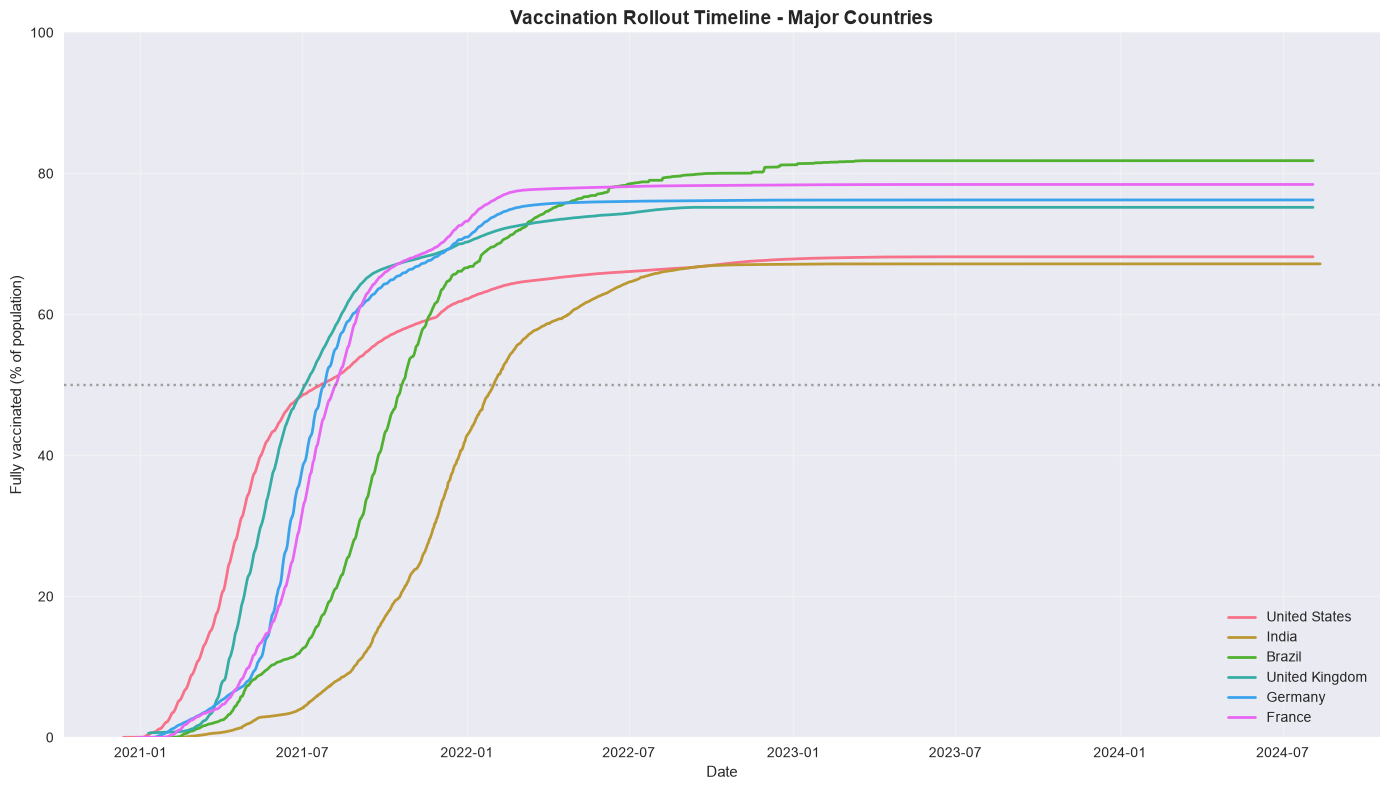

*** INSIGHT 4: Rollout speed (days from first dose to 50% fully vaccinated) ***
Countries with > 1M people that reached 50%: 87
Range: 97 to 766 days; median 257
5 fastest: Israel (97), Mongolia (117), Uruguay (124), Cuba (148), Qatar (150)
5 slowest: Bolivia (566), Uzbekistan (572), Mozambique (624), Turkmenistan (707), Sierra Leone (766)
Major countries: United States (221), India (380), Brazil (277), United Kingdom (176), Germany (211), France (223)


In [14]:
major_countries = ['United States', 'India', 'Brazil', 'United Kingdom', 'Germany', 'France']
fig, ax = plt.subplots(figsize=(14, 8))
for c in major_countries:
    d = df_countries[(df_countries['location'] == c)].dropna(subset=['vaccination_rate'])
    ax.plot(d['date'], d['vaccination_rate'], label=c, linewidth=2)
ax.axhline(50, color='grey', linestyle=':', alpha=0.7)
ax.set_xlabel('Date'); ax.set_ylabel('Fully vaccinated (% of population)'); ax.set_ylim(0, 100)
ax.set_title('Vaccination Rollout Timeline - Major Countries', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3); ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/vaccination_timeline.png', dpi=300, bbox_inches='tight')
plt.show()

big = totals[(totals['population'] > 1_000_000) & totals['days_to_50'].notna()]['days_to_50'].sort_values()
print("*** INSIGHT 4: Rollout speed (days from first dose to 50% fully vaccinated) ***")
print(f"Countries with > 1M people that reached 50%: {len(big)}")
print(f"Range: {big.min():.0f} to {big.max():.0f} days; median {big.median():.0f}")
print("5 fastest:", ', '.join(f'{n} ({v:.0f})' for n, v in big.head(5).items()))
print("5 slowest:", ', '.join(f'{n} ({v:.0f})' for n, v in big.tail(5).items()))
print("Major countries:", ', '.join(f"{c} ({totals.loc[c, 'days_to_50']:.0f})" for c in major_countries
                                     if c in totals.index and pd.notna(totals.loc[c, 'days_to_50'])))

key_numbers['insight4'] = {
    'n_countries_reaching_50': int(len(big)), 'min_days': float(big.min()), 'max_days': float(big.max()),
    'median_days': float(big.median()),
    'fastest5': {n: float(v) for n, v in big.head(5).items()},
    'slowest5': {n: float(v) for n, v in big.tail(5).items()},
}

### Insight 5 - Regional distribution

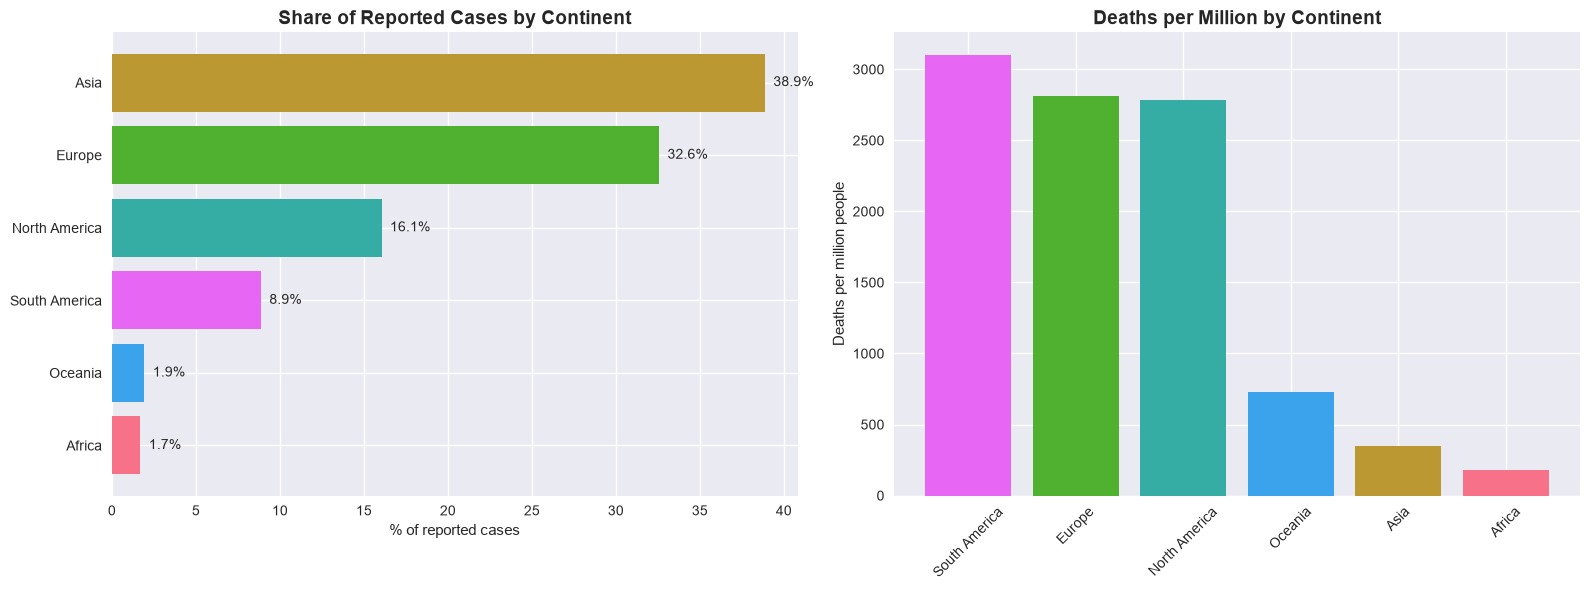

*** INSIGHT 5: Regional distribution ***
                     cases     deaths  cases_share_pct  cases_per_million  deaths_per_million
continent                                                                                    
Africa          13145540.0   259118.0              1.7             9213.7               181.6
Asia           301532347.0  1637249.0             38.9            63864.3               346.8
Europe         252642589.0  2099271.0             32.6           338831.4              2815.4
North America  124492666.0  1671178.0             16.1           207375.9              2783.8
Oceania         15003352.0    32918.0              1.9           333119.8               730.9
South America   68809418.0  1355939.0              8.9           157524.7              3104.1
Caution: reported cases depend heavily on testing; low numbers in some regions likely reflect underreporting.


In [15]:
region = totals.groupby('continent').agg(
    cases=('total_cases', 'sum'), deaths=('total_deaths', 'sum'), pop=('population', 'sum'))
region['cases_share_pct'] = region['cases'] / region['cases'].sum() * 100
region['cases_per_million'] = region['cases'] / region['pop'] * 1e6
region['deaths_per_million'] = region['deaths'] / region['pop'] * 1e6

palette = dict(zip(sorted(region.index), sns.color_palette('husl', len(region))))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
r1 = region.sort_values('cases_share_pct')
ax1.barh(r1.index, r1['cases_share_pct'], color=[palette[c] for c in r1.index])
for i, v in enumerate(r1['cases_share_pct']):
    ax1.text(v + 0.5, i, f'{v:.1f}%', va='center')
ax1.set_title('Share of Reported Cases by Continent', fontsize=14, fontweight='bold'); ax1.set_xlabel('% of reported cases')

r2 = region.sort_values('deaths_per_million', ascending=False)
ax2.bar(r2.index, r2['deaths_per_million'], color=[palette[c] for c in r2.index])
ax2.set_title('Deaths per Million by Continent', fontsize=14, fontweight='bold')
ax2.set_ylabel('Deaths per million people'); ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/regional_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("*** INSIGHT 5: Regional distribution ***")
print(region[['cases', 'deaths', 'cases_share_pct', 'cases_per_million', 'deaths_per_million']].round(1).to_string())
print("Caution: reported cases depend heavily on testing; low numbers in some regions likely reflect underreporting.")

key_numbers['insight5'] = region[['cases', 'deaths', 'cases_per_million', 'deaths_per_million']].round(1).to_dict(orient='index')

### Insight 6 - Doubling time during the first wave of 2020

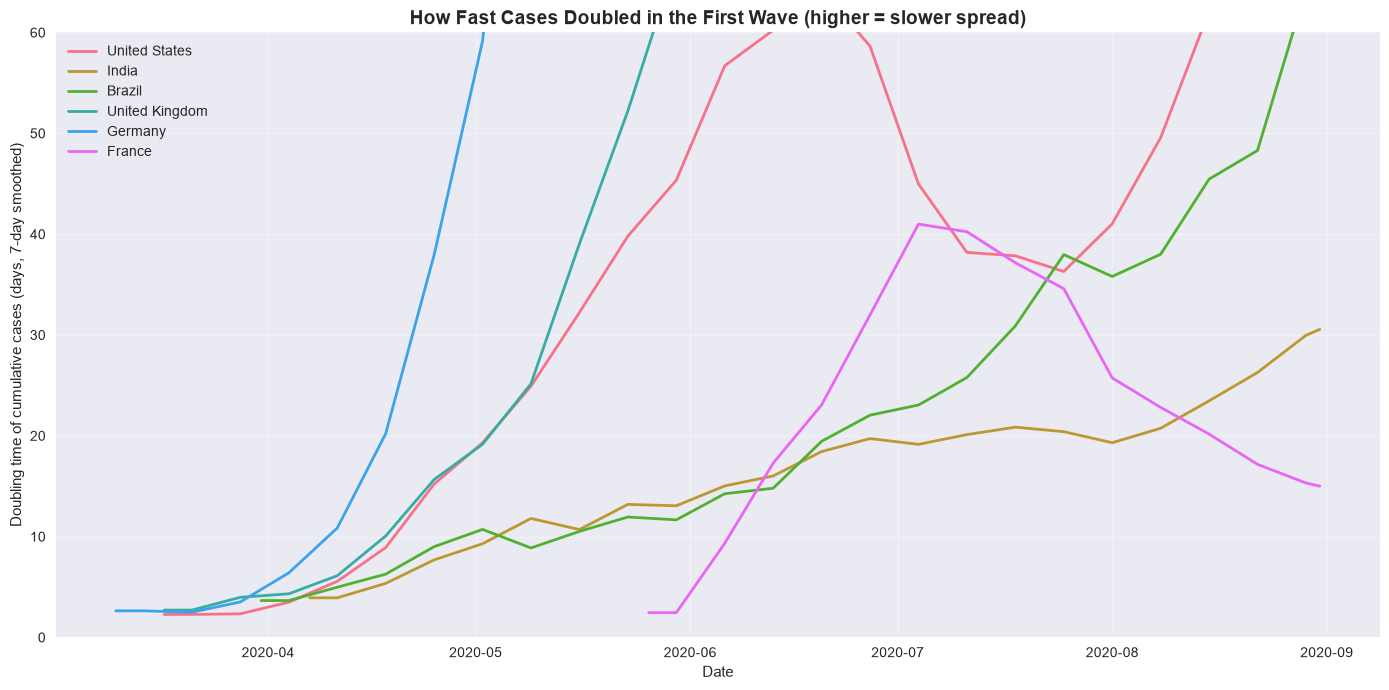

*** INSIGHT 6: Doubling time ***
Median doubling time across countries, Mar-Apr 2020: 9.6 days


In [16]:
fig, ax = plt.subplots(figsize=(14, 7))
for c in major_countries:
    d = df_countries[(df_countries['location'] == c) & (df_countries['date'] >= '2020-03-01')
                     & (df_countries['date'] <= '2020-08-31')].dropna(subset=['doubling_time_days'])
    ax.plot(d['date'], d['doubling_time_days'].rolling(7, min_periods=3).mean(), label=c, linewidth=2)
ax.set_ylim(0, 60)
ax.set_xlabel('Date'); ax.set_ylabel('Doubling time of cumulative cases (days, 7-day smoothed)')
ax.set_title('How Fast Cases Doubled in the First Wave (higher = slower spread)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/doubling_time_2020.png', dpi=300, bbox_inches='tight')
plt.show()

early = df_countries[(df_countries['date'] >= '2020-03-01') & (df_countries['date'] <= '2020-04-30')]
med = early.groupby('location')['doubling_time_days'].median().dropna()
print("*** INSIGHT 6: Doubling time ***")
print(f"Median doubling time across countries, Mar-Apr 2020: {med.median():.1f} days")
key_numbers['insight6'] = {'median_doubling_days_mar_apr_2020': float(med.median())}

## 5. Save Cleaned Dataset and Key Numbers

In [17]:
essential_columns = [
    'iso_code', 'continent', 'location', 'date', 'population',
    'total_cases', 'new_cases', 'total_deaths', 'new_deaths',
    'people_vaccinated', 'people_fully_vaccinated',
    'case_fatality_rate', 'vaccination_rate',
    'new_cases_7day_avg', 'new_deaths_7day_avg', 'doubling_time_days',
]
df_cleaned = df_countries[essential_columns].copy()
num_cols = df_cleaned.select_dtypes(include=[np.number]).columns
df_cleaned[num_cols] = df_cleaned[num_cols].round(2)
df_cleaned.to_csv(CLEAN_PATH, index=False)

size_mb = os.path.getsize(CLEAN_PATH) / 1024 / 1024
print(f"Saved {CLEAN_PATH}: shape {df_cleaned.shape}, {size_mb:.1f} MB  (GitHub limit: 100 MB)")

with open(f'{OUT_DIR}/key_numbers.json', 'w') as f:
    json.dump(key_numbers, f, indent=2, default=str)
print(f"Saved {OUT_DIR}/key_numbers.json (use these numbers in the executive summary)")

Saved ../data/covid_data_cleaned.csv: shape (395311, 16), 37.4 MB  (GitHub limit: 100 MB)
Saved ../outputs/key_numbers.json (use these numbers in the executive summary)


## 6. Data Assumptions and Limitations

In [18]:
print("ASSUMPTIONS")
print("- Only real countries kept: continent aggregates and OWID_* entries (UK nations, N. Cyprus, Kosovo) removed.")
print("- Cumulative columns forward-filled within each country; leading gaps left missing (not zero).")
print("- Negative daily values treated as data corrections and set to missing.")
print("- Vaccination rate capped at 100%.")
print("- CFR = total deaths / total cases * 100 (reported figures).")
print("- Doubling time = ln(2) / (ln(cases_t / cases_t-7) / 7), only with >= 1,000 cases; values above 365 days set to missing.")
print("- Rollout speed = days from the first dose record to 50% fully vaccinated; countries whose first")
print("  record is already > 5% of the population are excluded; rankings use countries with > 1M people.")
print()
print("LIMITATIONS")
print("- Underreporting of cases and deaths, especially early on and in low-income countries.")
print("- Testing strategies differ, so CFR and case counts are not strictly comparable.")
print("- Some countries switched to weekly reporting, and batch reporting creates spikes.")
print("- Country-level correlations do not prove causation (age, healthcare, variants, timing).")
print(f"- Data cutoff: {df['date'].max().date()} (OWID dataset no longer updated after Aug 2024).")

ASSUMPTIONS
- Only real countries kept: continent aggregates and OWID_* entries (UK nations, N. Cyprus, Kosovo) removed.
- Cumulative columns forward-filled within each country; leading gaps left missing (not zero).
- Negative daily values treated as data corrections and set to missing.
- Vaccination rate capped at 100%.
- CFR = total deaths / total cases * 100 (reported figures).
- Doubling time = ln(2) / (ln(cases_t / cases_t-7) / 7), only with >= 1,000 cases; values above 365 days set to missing.
- Rollout speed = days from the first dose record to 50% fully vaccinated; countries whose first
  record is already > 5% of the population are excluded; rankings use countries with > 1M people.

LIMITATIONS
- Underreporting of cases and deaths, especially early on and in low-income countries.
- Testing strategies differ, so CFR and case counts are not strictly comparable.
- Some countries switched to weekly reporting, and batch reporting creates spikes.
- Country-level correlations do not 